In [1]:
#Shriyans Singh 114807762
#CSE 351 HW 4
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score,f1_score,confusion_matrix#https://scikit-learn.org/stable/getting_started.html very nice, i did google it to get these tho
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler#https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

In [2]:
#t1
#BUS 367 is coming in alot of help surprisingly
energy=pd.read_csv('energy_data.csv')
energy['Date & Time']=pd.to_datetime(energy['Date & Time'])
energy['Date']=energy['Date & Time'].dt.normalize() #https://www.geeksforgeeks.org/pandas/pandas-series-dt-normalize/
daily_energy=energy.groupby('Date')[['use [kW]']].sum()
weath=pd.read_csv('weather_data.csv')
weath['Date']=pd.to_datetime(weath['time'],unit='s').dt.normalize()#https://www.geeksforgeeks.org/pandas/pandas-series-dt-normalize/
weather_num=weath.drop(columns=['time','icon','summary'])
daily_weather=weather_num.groupby('Date').mean()
merge=daily_weather.join(daily_energy,how='inner')#https://www.geeksforgeeks.org/pandas/pandas-join-dataframes/
print(merge.shape,"NaNS:",merge.isna().sum().sum())
print(merge['use [kW]'].describe())
#The weather data was hourly so i changed it to be averaged per day, while energy is summed for each day as stated in the instructions. icon and summary were dropped because they were text columns and weren't necessary.

(365, 11) NaNS: 0
count    365.000000
mean      31.819442
std       14.466709
min       10.572219
25%       21.660309
50%       27.108372
75%       37.879129
max       96.443073
Name: use [kW], dtype: float64


In [3]:
#t2
trainingData=merge[merge.index.month<12]
testingData=merge[merge.index.month==12]#want to predict in december, so use that as testing
xTrain=trainingData.drop(columns=['use [kW]'])
yTrain=trainingData['use [kW]']
xTest=testingData.drop(columns=['use [kW]'])
yTest=testingData['use [kW]']
print(trainingData.shape,testingData.shape)

(334, 11) (31, 11)


RMSE: 8.740566311136988
R2: -0.5169732667448281
Baseline Model RMSE: 7.387204123945254


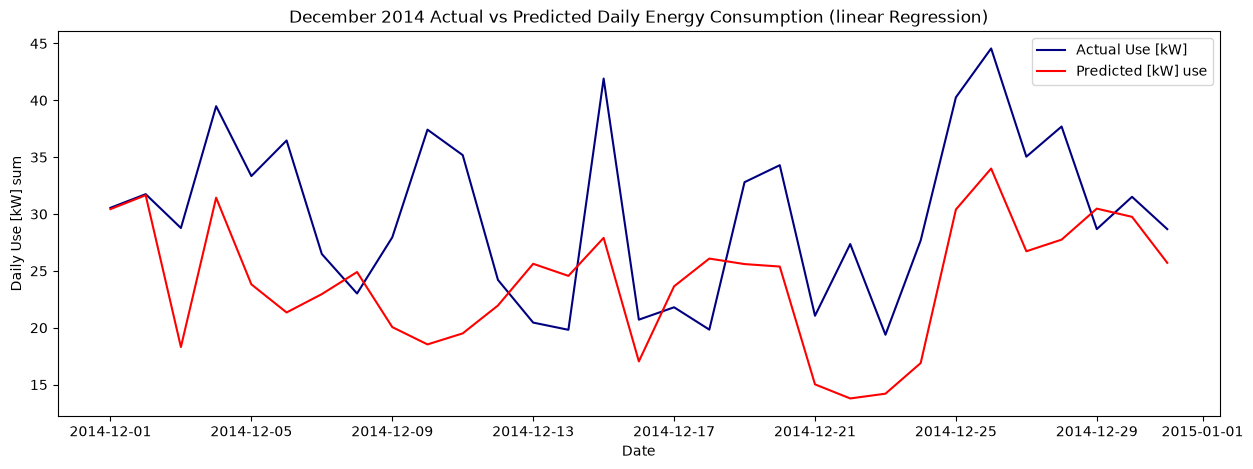

In [4]:
#t3
lModel=LinearRegression()
lModel.fit(xTrain,yTrain)
yPred=lModel.predict(xTest)
#print("MSE:",mean_squared_error(yTest,yPred)) #from autocomplete, figured i would use it anyways
RMSE=np.sqrt(mean_squared_error(yTest,yPred))
print("RMSE:",RMSE)
print("R2:",r2_score(yTest,yPred))
#baselinemodel rmse to compre, new model shou.d have smaller rmse to be considered good
baseRMSE=np.sqrt(mean_squared_error(yTest,np.full(len(yTest),yTrain.mean())))
print("Baseline Model RMSE:", baseRMSE)
#csv dump
lOut=pd.DataFrame({'date':xTest.index.strftime('%Y-%m-%d'),'predicted use [kW]':yPred})#https://www.bairesdev.com/tools/strftime/, column of dates
#now columns of val predicted
lOut.to_csv('predicted_val_of_lin_regression.csv',index=False)#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html


#for t6 plot
fig,ax=plt.subplots(figsize=(15,5))
ax.plot(yTest.index,yTest.values,color='navy',label='Actual Use [kW]')
ax.plot(yTest.index,yPred, color='red',label='Predicted [kW] use')
ax.set_title('December 2014 Actual vs Predicted Daily Energy Consumption (linear Regression)')
ax.set_xlabel('Date');
ax.set_ylabel('Daily Use [kW] sum')
ax.legend()
plt.show()

##RMSE of 8.740566 is far worse than the baseline of 7.387204, and R^2 = -.51697, so the model is working pretty badly. 
#The consumption in july is around 55 while hte fall and winter is closer to 30, so AC is likely a big factor. 
#Weather is a poor predictor of daily usage as the correlation is about .37 with temperature and daily usage


q4-log reg of if the temp is high or low (greater than equal to 35 is high, less than 35 is low

In [5]:
#t4
yTraintemp=(trainingData['temperature']>=35).astype(int)
yTesttemp=(testingData['temperature']>=35).astype(int)#did < at first
featureCol=[i for i in xTrain.columns if i!= 'temperature']
sScale=StandardScaler().fit(xTrain[featureCol])
xtrainS=sScale.transform(xTrain[featureCol])
xtestS=sScale.transform(xTest[featureCol])
# Using LogisticRegression for binary classification
logModel = LogisticRegression()
logModel.fit(xtrainS,yTraintemp)
yPredtemp=logModel.predict(xtestS)
print("F1: ",f1_score(yTesttemp,yPredtemp))
print("Confusion Matrix:")
print(confusion_matrix(yTesttemp,yPredtemp))
#csv dump bleh
csvDumpTemp=pd.DataFrame({'date':xTest.index.strftime('%Y-%m-%d'),'classification':yPredtemp})
csvDumpTemp.to_csv('predicted_val_of_log_regression.csv',index=False)
###F1 score is .72727....
#of the 13 high days 12 of them got caught while of the 18 low days 8 were called high
#data is 254 high,80 low, model leaning to high in colder months of the year, so model leans to high 
#and December is a colder month so that bias is hurting
#Since temp was the label, it was dropped as feature because to avoid leaking the answer
#although the dewPoint is still closley related so it might be a bit optimistic to the result

F1:  0.7272727272727273
Confusion Matrix:
[[10  8]
 [ 1 12]]


             Washer [kW]  AC [kW]
Time Period                      
Day               0.0046   0.0403
Night             0.0013   0.1466
             Washer [kW]  AC [kW]
Time Period                      
Day              81.2015  24.5049
Night            18.7985  75.4951


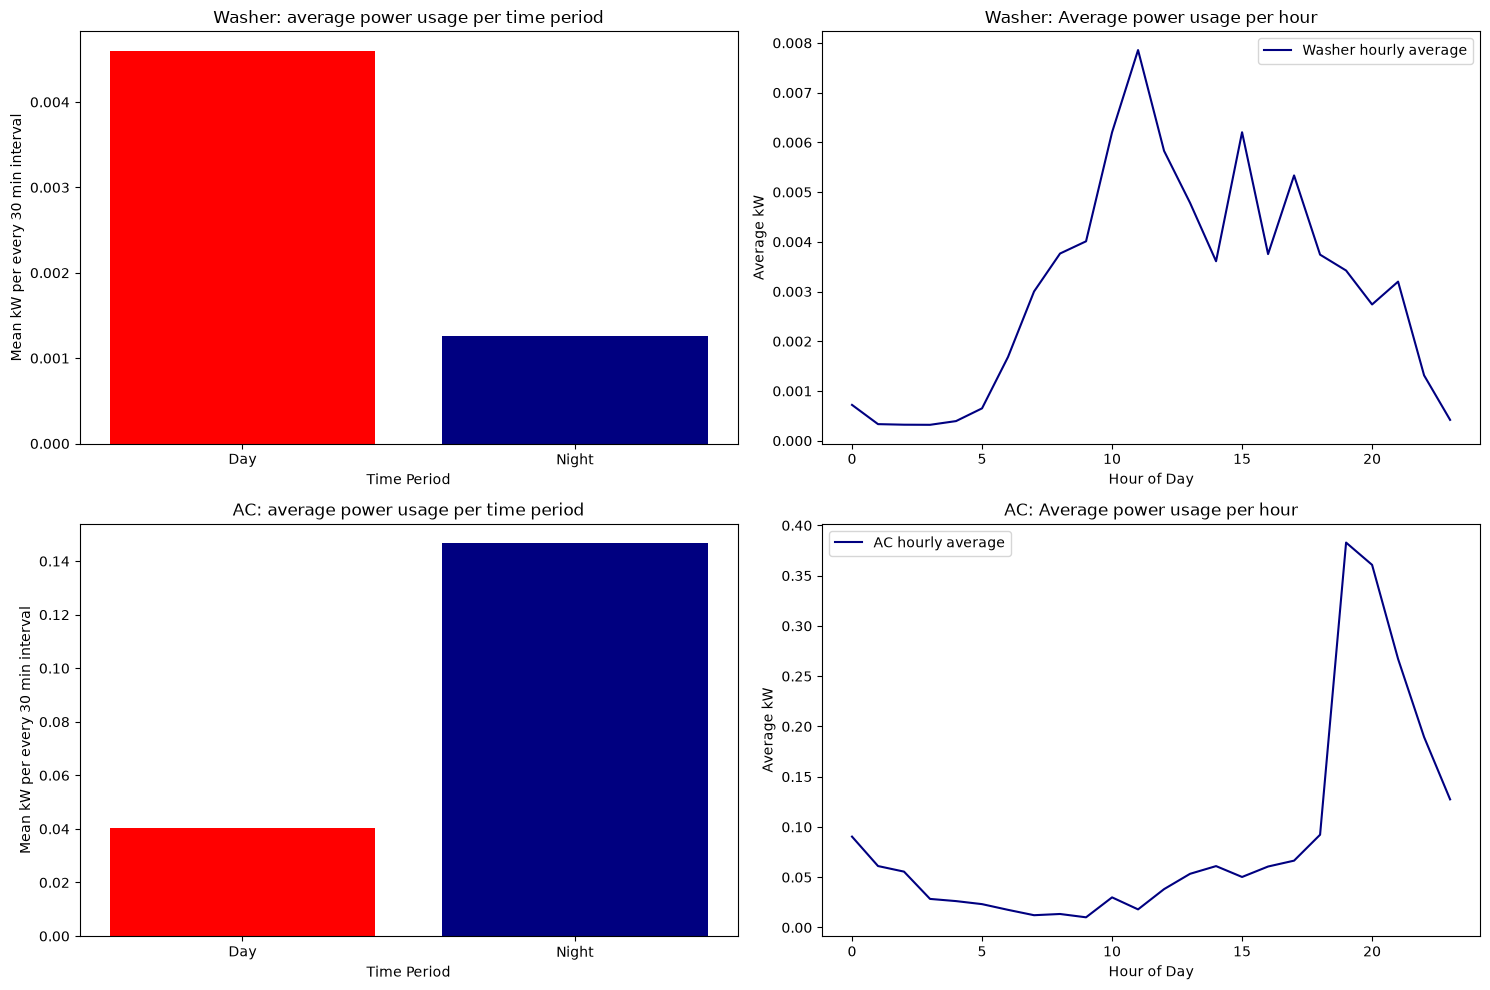

In [6]:
#t5
halfHour=energy['Date & Time'].dt.hour+(energy['Date & Time'].dt.minute/60)
energy['Time Period']=np.where((6<=halfHour)&(halfHour<19),'Day','Night')
energy['Hour']=energy['Date & Time'].dt.hour
devices=['Washer [kW]','AC [kW]']
avgUse=energy.groupby('Time Period')[devices].mean().loc[['Day','Night']]
totalEUse=energy.groupby('Time Period')[devices].sum().loc[['Day','Night']]
print(avgUse.round(4))#rounded to 4 cuz large
print((totalEUse/totalEUse.sum()*100).round(4))#rounded to 4 because it got pretty big
hourlyP=energy.groupby('Hour')[devices].mean()#profile per 24hr
#separation of th axes because different scales for the two devices
fig,ax=plt.subplots(2,2,figsize=(15,10)) #20,10 is wayyy too big
for i, dev in enumerate(devices):
    n=dev.replace(' [kW]','')#cleanup
    ax[i,0].bar(avgUse.index,avgUse[dev],color=['red','navy'])
    ax[i,0].set_xlabel('Time Period')
    ax[i,0].set_ylabel('Mean kW per every 30 min interval')
    ax[i,0].set_title(f'{n}: average power usage per time period')
    ax[i,1].plot(hourlyP.index,hourlyP[dev],color='navy',label=f'{n} hourly average')
    ax[i,1].set_title(f'{n}: Average power usage per hour')
    ax[i,1].set_xlabel('Hour of Day')
    ax[i,1].set_ylabel('Average kW')
    ax[i,1].legend()
plt.tight_layout();
plt.show()

#The AC appears to be 75.5% at night, and 24.5% in the Day
#AC peaks at hour 19-7PM- and it is around .38 kW
#AC is lowest in the morning
#Washer peaks at 11AM
#The Washer on the other hand is 81% in the Day and 18.8% in the night. 
#Thus the washer is not only during the day
#i compared per interval averages because the day interval of 13 hours was longer than night of 11 hours